In [1]:
# Prerequisites
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.dpi"] = 300
plt.rcParams["figure.figsize"] = (12, 5)

In [2]:
from ponds import PONDS, GAUSS, SIGMOID
import matplotlib.pyplot as plt

## Generating an Abrupt Shift Time Series

### Initializing `PONDS`

`PONDS`' simplest use case is to generate a single time series which is perturbed with some white noise and a backgroud trend. The user can specify the length of the series and parameters for the perturbation. The created class object will contain a data-xarray.Dataset containing a `(time_size x 1 x 1)` time series called `ts`, representing an arbitrary climate variable:

In [3]:
from ponds import PONDS

background_noise = 0.05
background_trend = 0.002

pd = PONDS(
    time_size=200,
    background_noise=background_noise,
    background_trend=background_trend,
)

pd.data


<xarray.Dataset> Size: 3kB
Dimensions:  (time: 200, lat: 1, lon: 1)
Coordinates:
  * time     (time) float64 2kB 0.0 1.005 2.01 3.015 ... 197.0 198.0 199.0 200.0
  * lat      (lat) float64 8B -90.0
  * lon      (lon) float64 8B -180.0
Data variables:
    ts       (time, lat, lon) float64 2kB 0.02484 -0.004903 ... 0.4009 0.3429

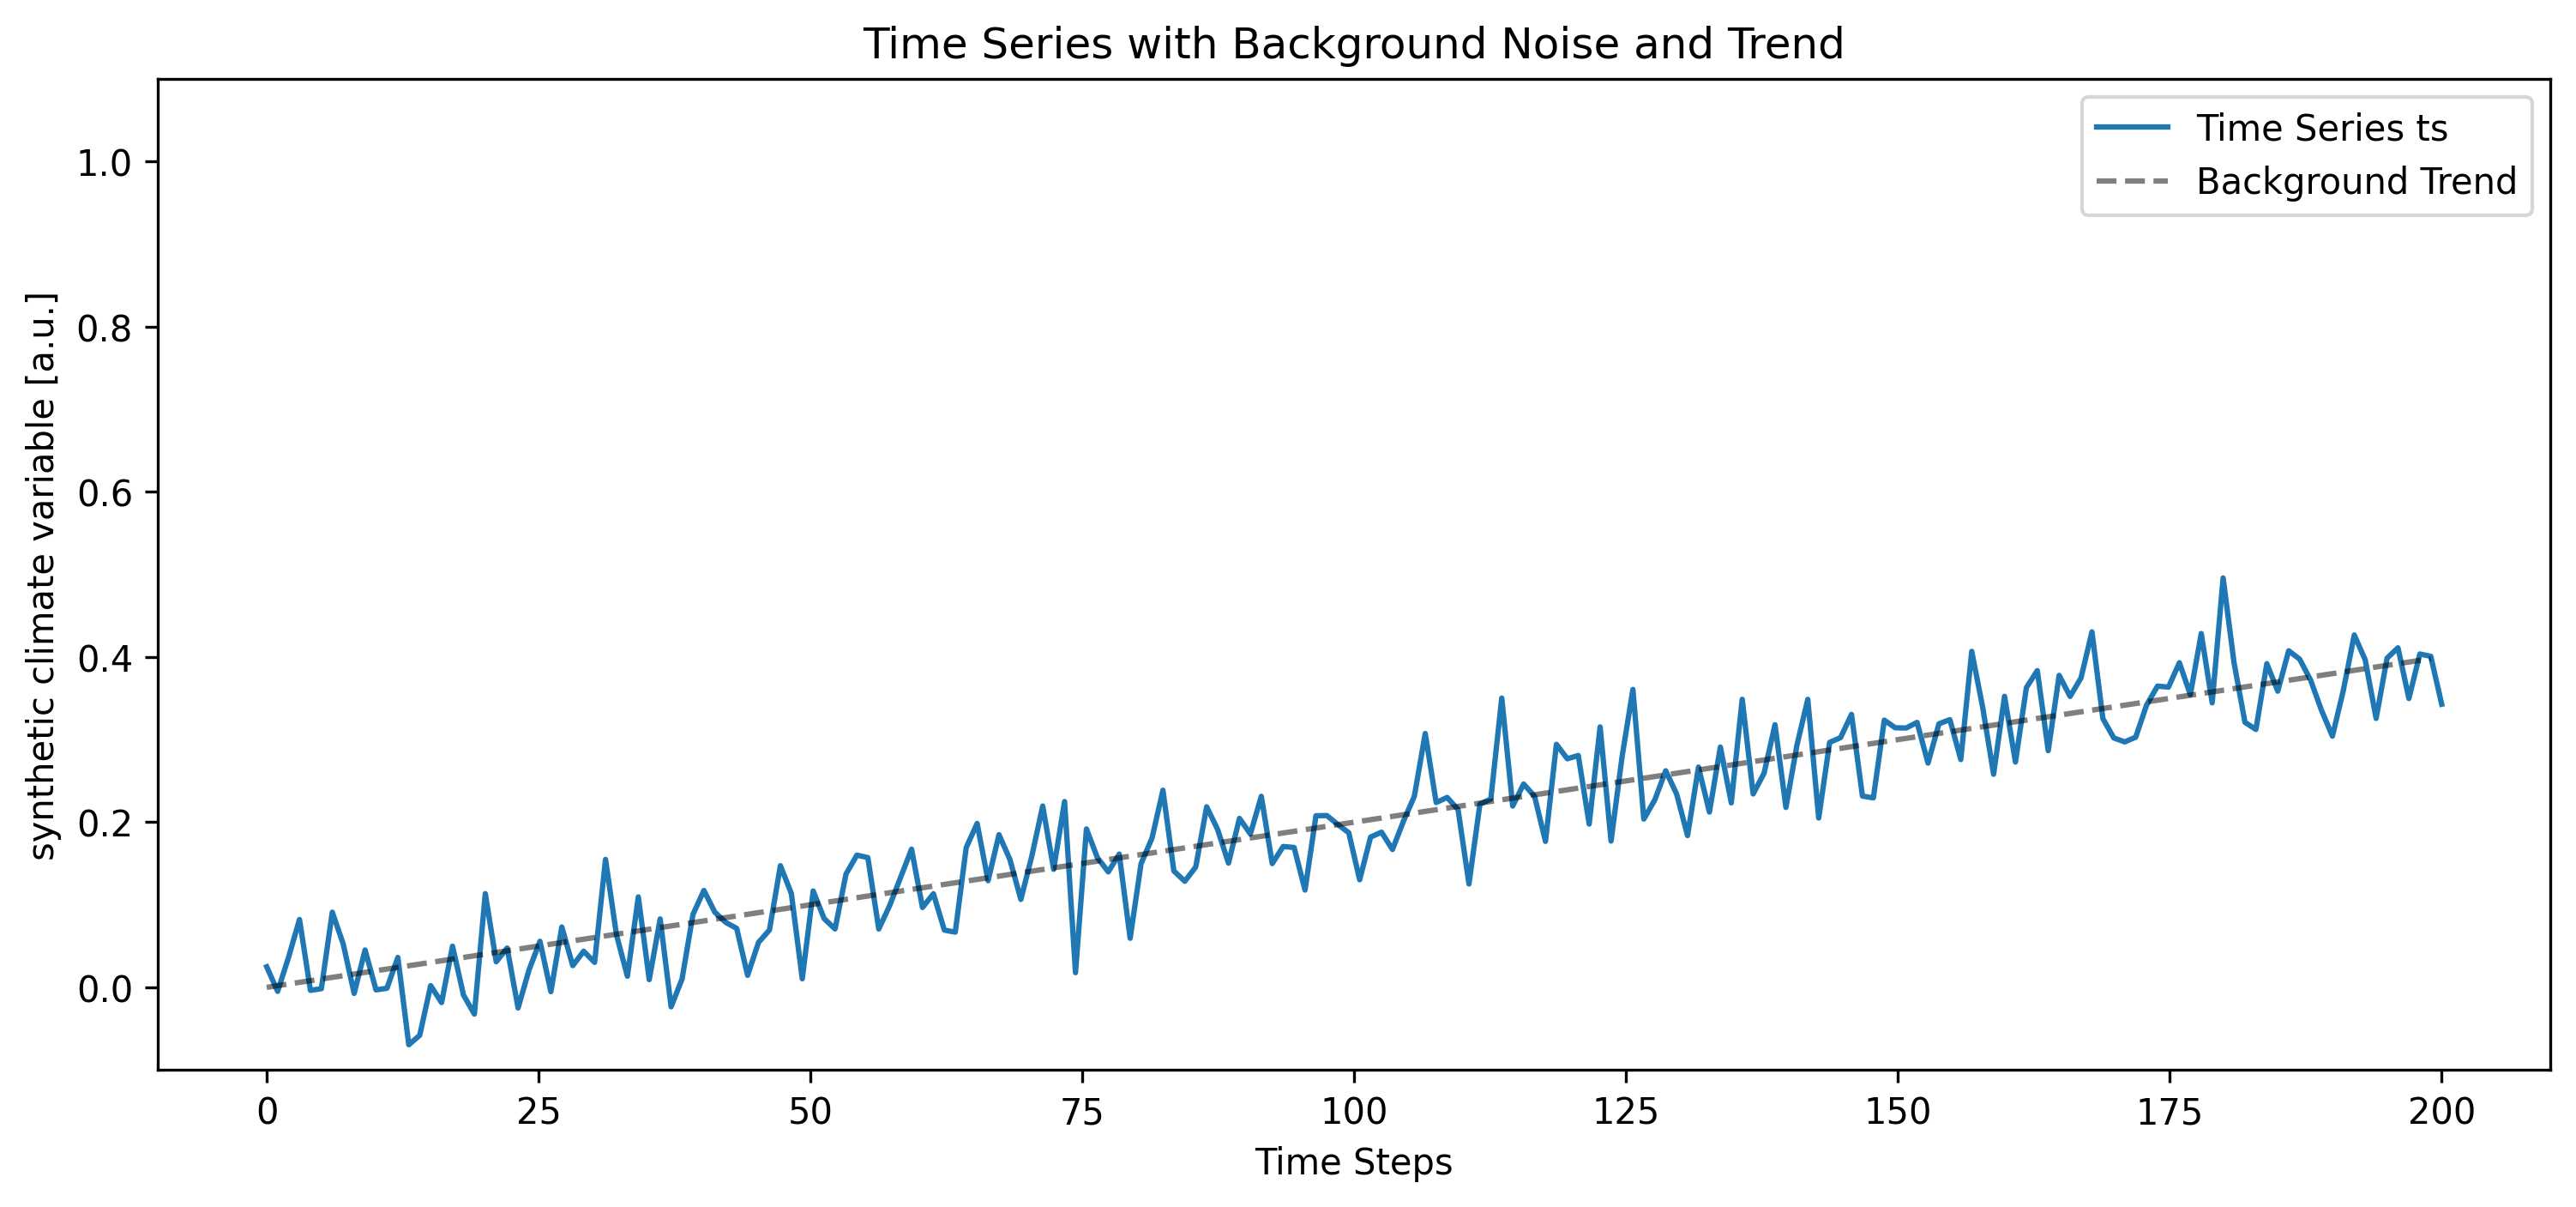

In [4]:
# plot generated time series
pd.data.ts.plot(label="Time Series ts")
plt.ylim(-0.1, 1.1)

# add background trend
X = np.arange(0, pd.time_size)
plt.plot(X, background_trend * X, linestyle="--",
         label="Background Trend", color="black", alpha=0.5)

# eyecandy
plt.title("Time Series with Background Noise and Trend")
plt.xlabel("Time Steps")
plt.ylabel("synthetic climate variable [a.u.]")
plt.legend()
plt.show()

### Adding Shifts

This time series now can be altered by adding customizable shifts. This is done with the class-function `PONDS.add_shift()`. The simplest version of an abrupt shift is a sigmoid-shift which can be applied by calling `shift_method = SIGMOID()`. In the following example, we add two sigmoid-shifts. The first will use randomly, the second is created with custom chosen variables.

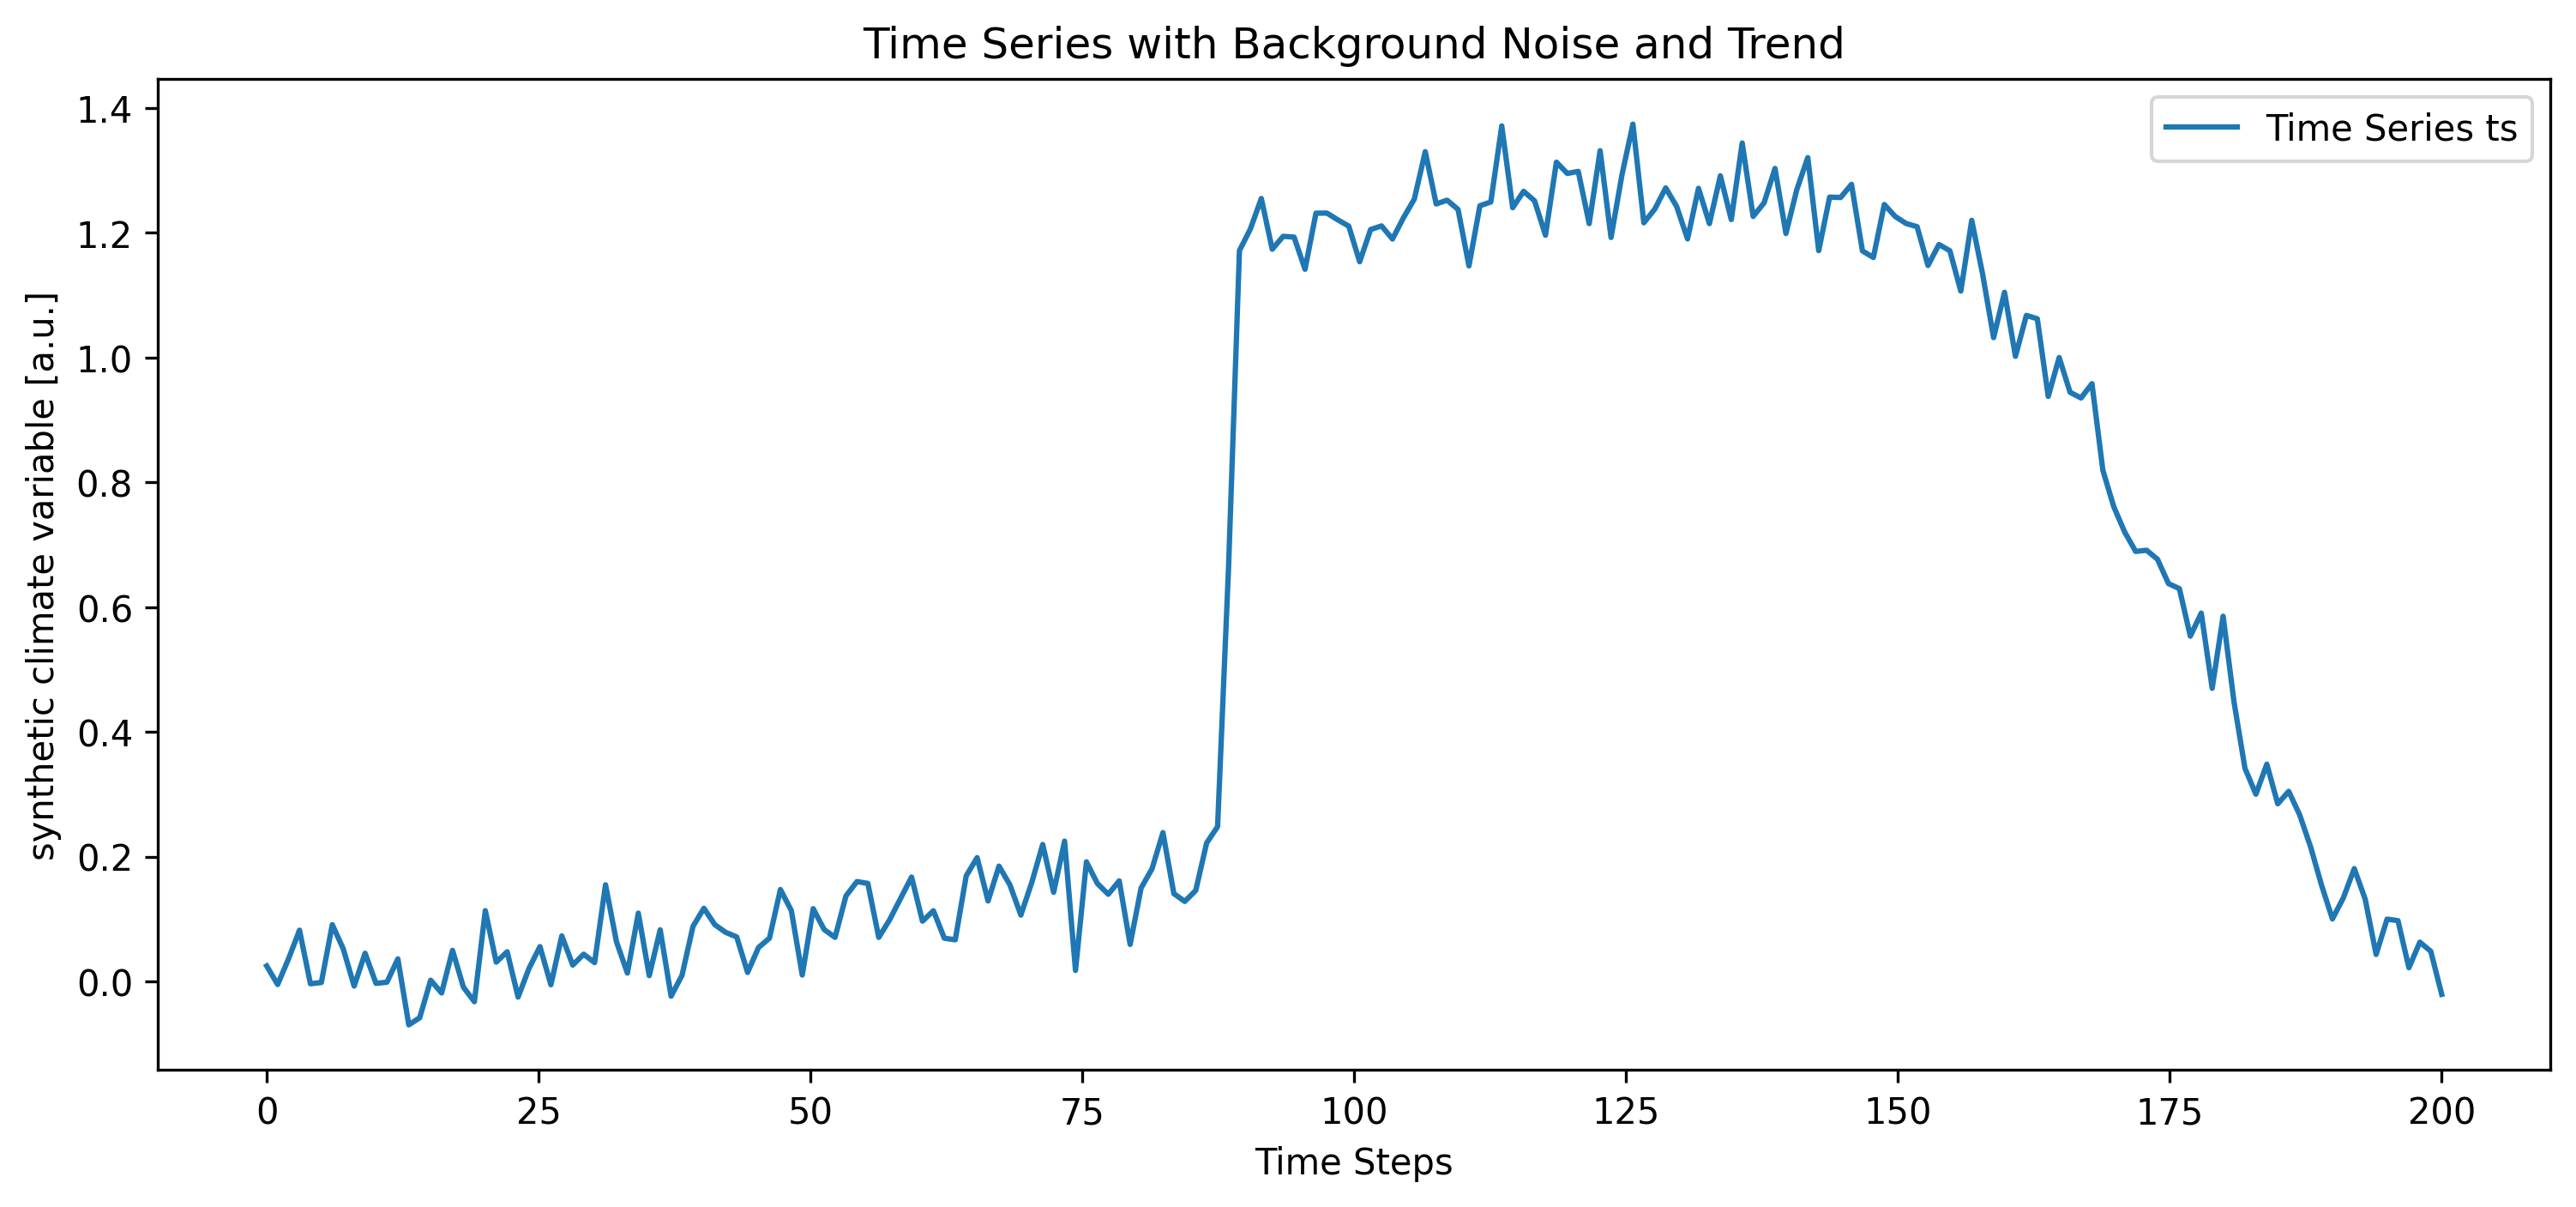

In [ ]:
from ponds import SIGMOID

# adding a random shift to the time series
pd.add_shift(
    random_seed=2,
    shift_method=SIGMOID(),
)

# adding a second, customized shift to the time series
shift_dict = {"shift_magnitude": -1.5,
              "shift_steepness": 0.1,}
pd.add_shift(
    random_seed=4,
    shift_method=SIGMOID(**shift_dict),
)

# plot generated time series
pd.data.ts.plot(label="Time Series ts")

# eyecandy
plt.title("Time Series with Background Noise and Trend")
plt.xlabel("Time Steps")
plt.ylabel("synthetic climate variable [a.u.]")
plt.legend()
plt.show()

## Generating a World Map of Synthetic Data

Using `PONDS` to generate a set of global, synthetic climate data is easy. Like before, we frist create an PONDS class object. This time, we also specify the number of grid points in latitudinal and longitudinal direction. The `PONDS` object is initialised with `(lat_size x lon_size)` grid cells, each containing individual noisy data following a given background trend. <br>

To add one abrupt shift, again, we call the function `PONDS.add_shift()`. This time, in addition to the `shift_method`, we also specify a `shape_method` argument which determines the shape of the blob in the grid. Hence, a spatial blob is generated which acts as a **shift-cluster**. Each grid cell in this cluster contains an abrupt shift of the same kind (**where** is the shift happening). This includes the point in time (**when** is the event happening). A blob clusters similar shift-events in space and time.

In [29]:
# initialize PONDS object
pd = PONDS(
    lat_size=20,
    lon_size=40,
    time_size=200,
    background_noise=0.05,
    background_trend=0.0002,
)

# add random shift
pd.add_shift(
    random_seed=1,
    shape_method=GAUSS(random_seed=1),
    shift_method=SIGMOID(),
)

# add shift with custom parameters
shift_dict = {
    "shift_steepness": 0.2,
    "shift_magnitude": 0.5,
}
pd.add_shift(
    random_seed=4,
    shape_method=GAUSS(random_seed=4),
    shift_method=SIGMOID(**shift_dict),
)

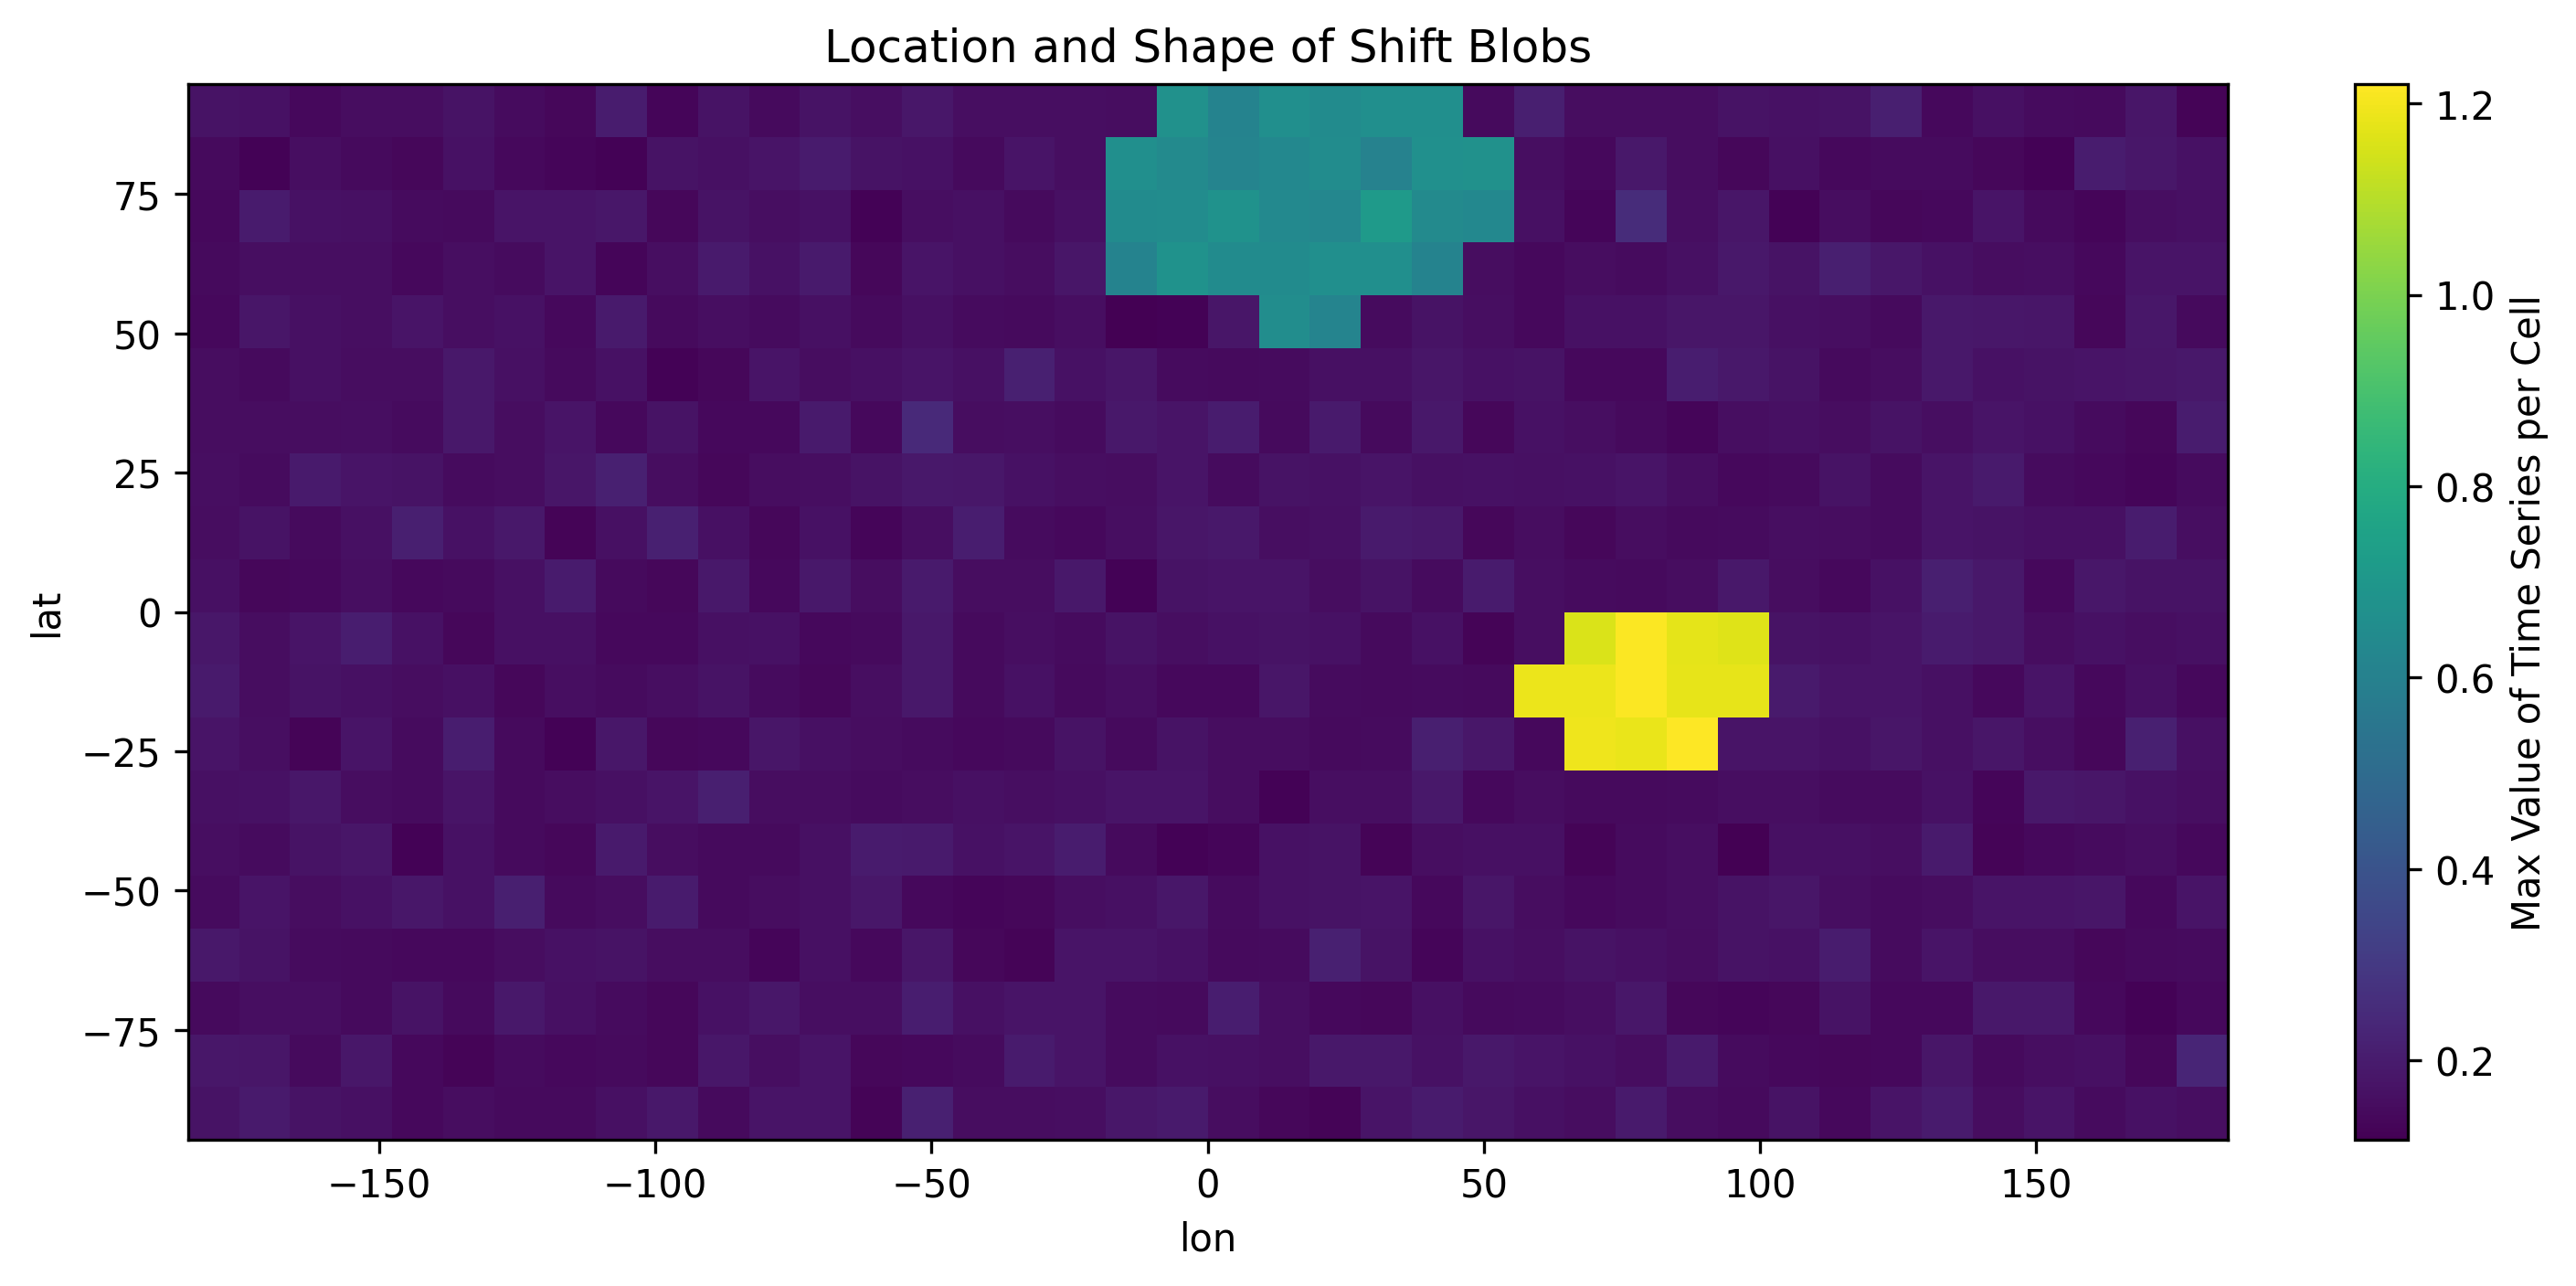

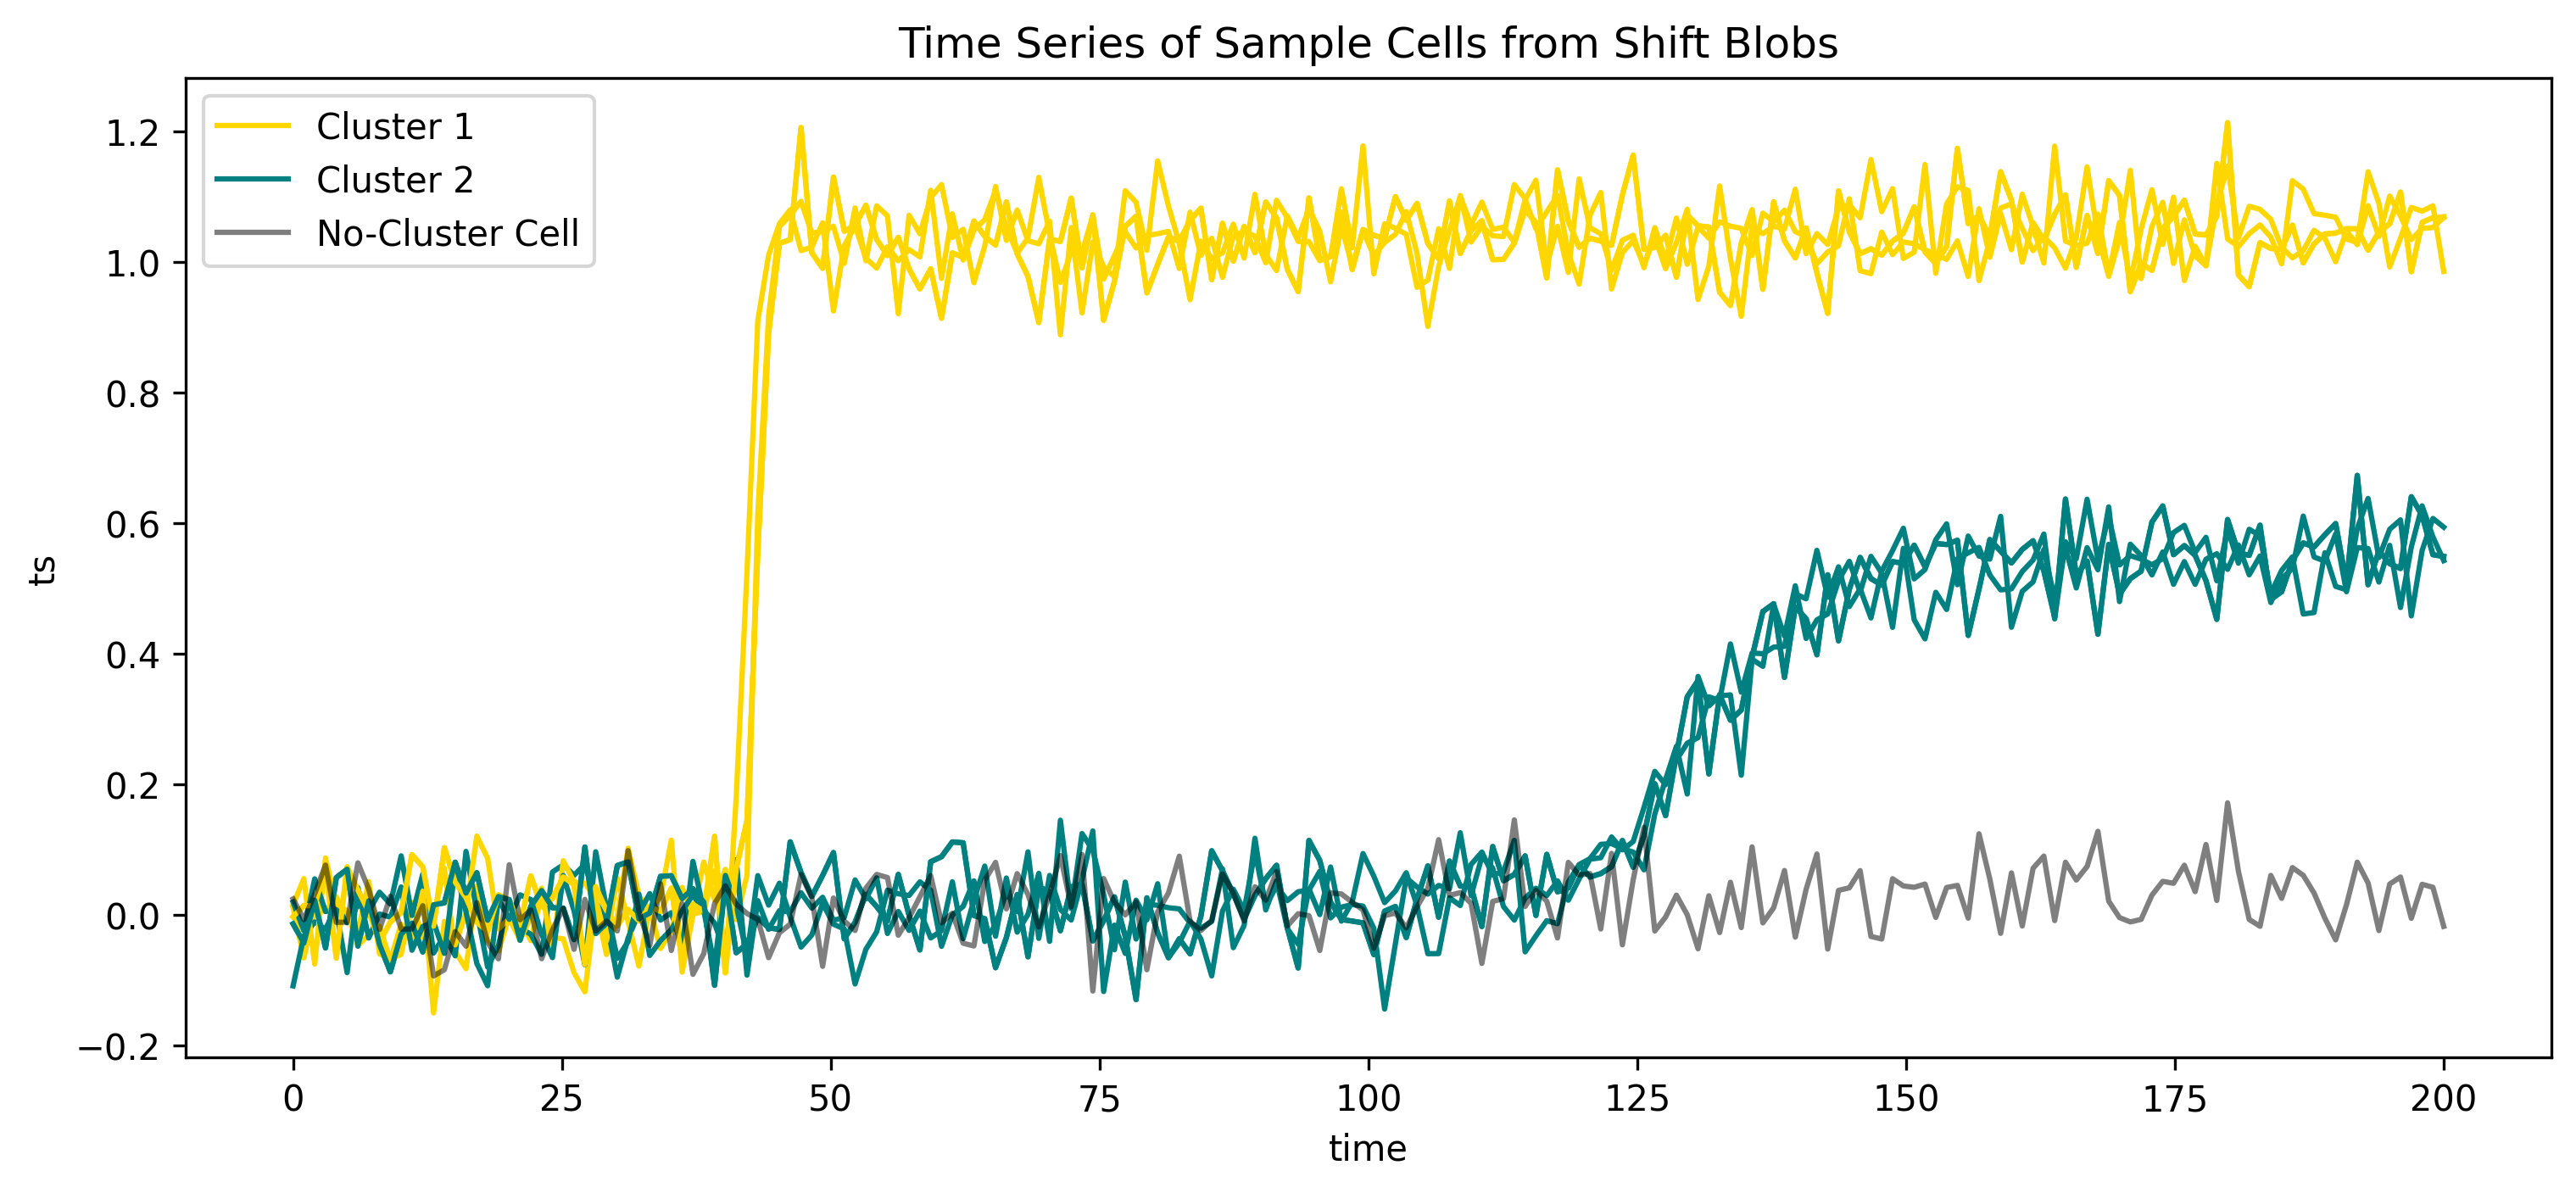

In [33]:
# look at generated time series data
pd.data.ts.max(dim="time").plot()
plt.gca().collections[0].colorbar.set_label("Max Value of Time Series per Cell")
plt.title("Location and Shape of Shift Blobs")
plt.show()

lat1, lon1 = 8, 28
lat2, lon2 = 17, 20
for i in range(3):
    pd.data.ts.isel(lat=lat1, lon=lon1+i).plot.line(x="time", color="gold")
    pd.data.ts.isel(lat=lat2, lon=lon2+i).plot.line(x="time", color="teal")
pd.data.ts.isel(lat=lat1, lon=lon1).plot.line(x="time", color="gold", label="Cluster 1")
pd.data.ts.isel(lat=lat2, lon=lon2).plot.line(x="time", color="teal", label="Cluster 2")
pd.data.ts.isel(lat=0, lon=0).plot.line(x="time", color="black", alpha=0.5, label="No-Cluster Cell")

plt.legend()
plt.title("Time Series of Sample Cells from Shift Blobs")
plt.show()

Each added shift is stored as an additional xr.DataArray within the `PONDS.data`. The default name for a shift-cluster is 'c' followed by a running number:

In [5]:
pd.data

<xarray.Dataset> Size: 2MB
Dimensions:  (time: 200, lat: 20, lon: 40)
Coordinates:
  * time     (time) float64 2kB 0.0 1.005 2.01 3.015 ... 197.0 198.0 199.0 200.0
  * lat      (lat) float64 160B -90.0 -80.53 -71.05 -61.58 ... 71.05 80.53 90.0
  * lon      (lon) float64 320B -180.0 -170.8 -161.5 ... 161.5 170.8 180.0
Data variables:
    ts       (time, lat, lon) float64 1MB 0.004967 0.003578 ... 0.4032 0.4073
    c1       (time, lat, lon) bool 160kB False False False ... False False False
    c2       (time, lat, lon) bool 160kB False False False ... False False False

## Using `PONDS` Data with `TOAD`

PONDS is developed in close proximity to TOAD and is therefore highly compatible with this abrupt shift detection package. Here, we want to demonstrate how a use case could look like.


In [6]:
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from ponds import PONDS, GAUSS, SIGMOID
from toad import TOAD
from toad.shifts_detection.methods import ASDETECT
from sklearn.cluster import HDBSCAN
from toad.visualisation.toad_plotter import PlotConfig

In [ ]:
# from ipywidgets import interact
def plot(random_seed=0, n_shifts=1):
    pd = PONDS(
        lat_size=20,
        lon_size=30,
        time_size=200,
        random_seed=random_seed,
        background_noise=0.05,
    )

    for n in range(n_shifts):
        print(f">> Adding Shift {n + 1}/{n_shifts}...")
        pd.add_shift(shape_method=GAUSS, shift_method=SIGMOID)

    data_ds = pd.data.ts.to_dataset(name="ts")
    td = TOAD(data_ds)
    td.compute_shifts("ts", ASDETECT())
    td.compute_clusters(
        "ts",
        HDBSCAN(min_cluster_size=10),
        shifts_filter_func=lambda x: abs(x) > 0.9,
    )

    plt.rcParams["figure.dpi"] = 300

    plotter = td.plotter(
        PlotConfig(
            map_frame=False,
            grid_labels=False,
        )
    )

    plotter.cluster_overview(
        "ts",
        range(10),
        cmap="tab10",
        timeseries_kwargs={},
        map_kwargs={"add_contour": False},
        figsize=(16, 5),
    )

    # Plot true shift locations
    # - Create a list of da_max for all relevant variables
    da_max_list = []
    for name, da in pd.data.data_vars.items():
        if name.startswith("c"):
            da_max = da.max(dim="time")
            da_max_list.append(da_max)
    # - Combine into a single DataArray by taking maximum across them
    combined_da_max = xr.concat(da_max_list, dim="new_dim").max(dim="new_dim")
    # - Plot the combined result
    fig, ax = plotter.map(figsize=(16, 4))
    combined_da_max.plot(
        ax=ax,
        cmap="Blues",
        vmin=0.1,
        vmax=1,
        add_colorbar=False,
    )
    combined_da_max.plot.contour(
        ax=ax, add_colorbar=False, colors=["blue"], vmin=0.1, vmax=1, levels=1
    )

    # Create custom legend
    legend_handles = [
        mpatches.Patch(color="blue", label="SIGMOID"),
    ]
    ax.legend(handles=legend_handles, loc="lower left")
    ax.set_title("True shift locations")

    # plot cluster timeseries
    fig, axs = plt.subplots(2, 1, figsize=(16, 4))
    plotter.cluster_timeseries("ts", td.get_cluster_ids("ts"), ax=axs[0])

    # plot data timeseries
    td.data.ts.toad.to_timeseries().plot.line(
        x="time", add_legend=False, color="k", alpha=0.1, ax=axs[1]
    )
    axs[0].set_title(f"Cluster {td.get_cluster_ids('ts')} timeseries")
    axs[1].set_title("All data timeseries")
    fig.tight_layout()

>> Adding Shift 1/3...
>> Adding Shift 2/3...
>> Adding Shift 3/3...


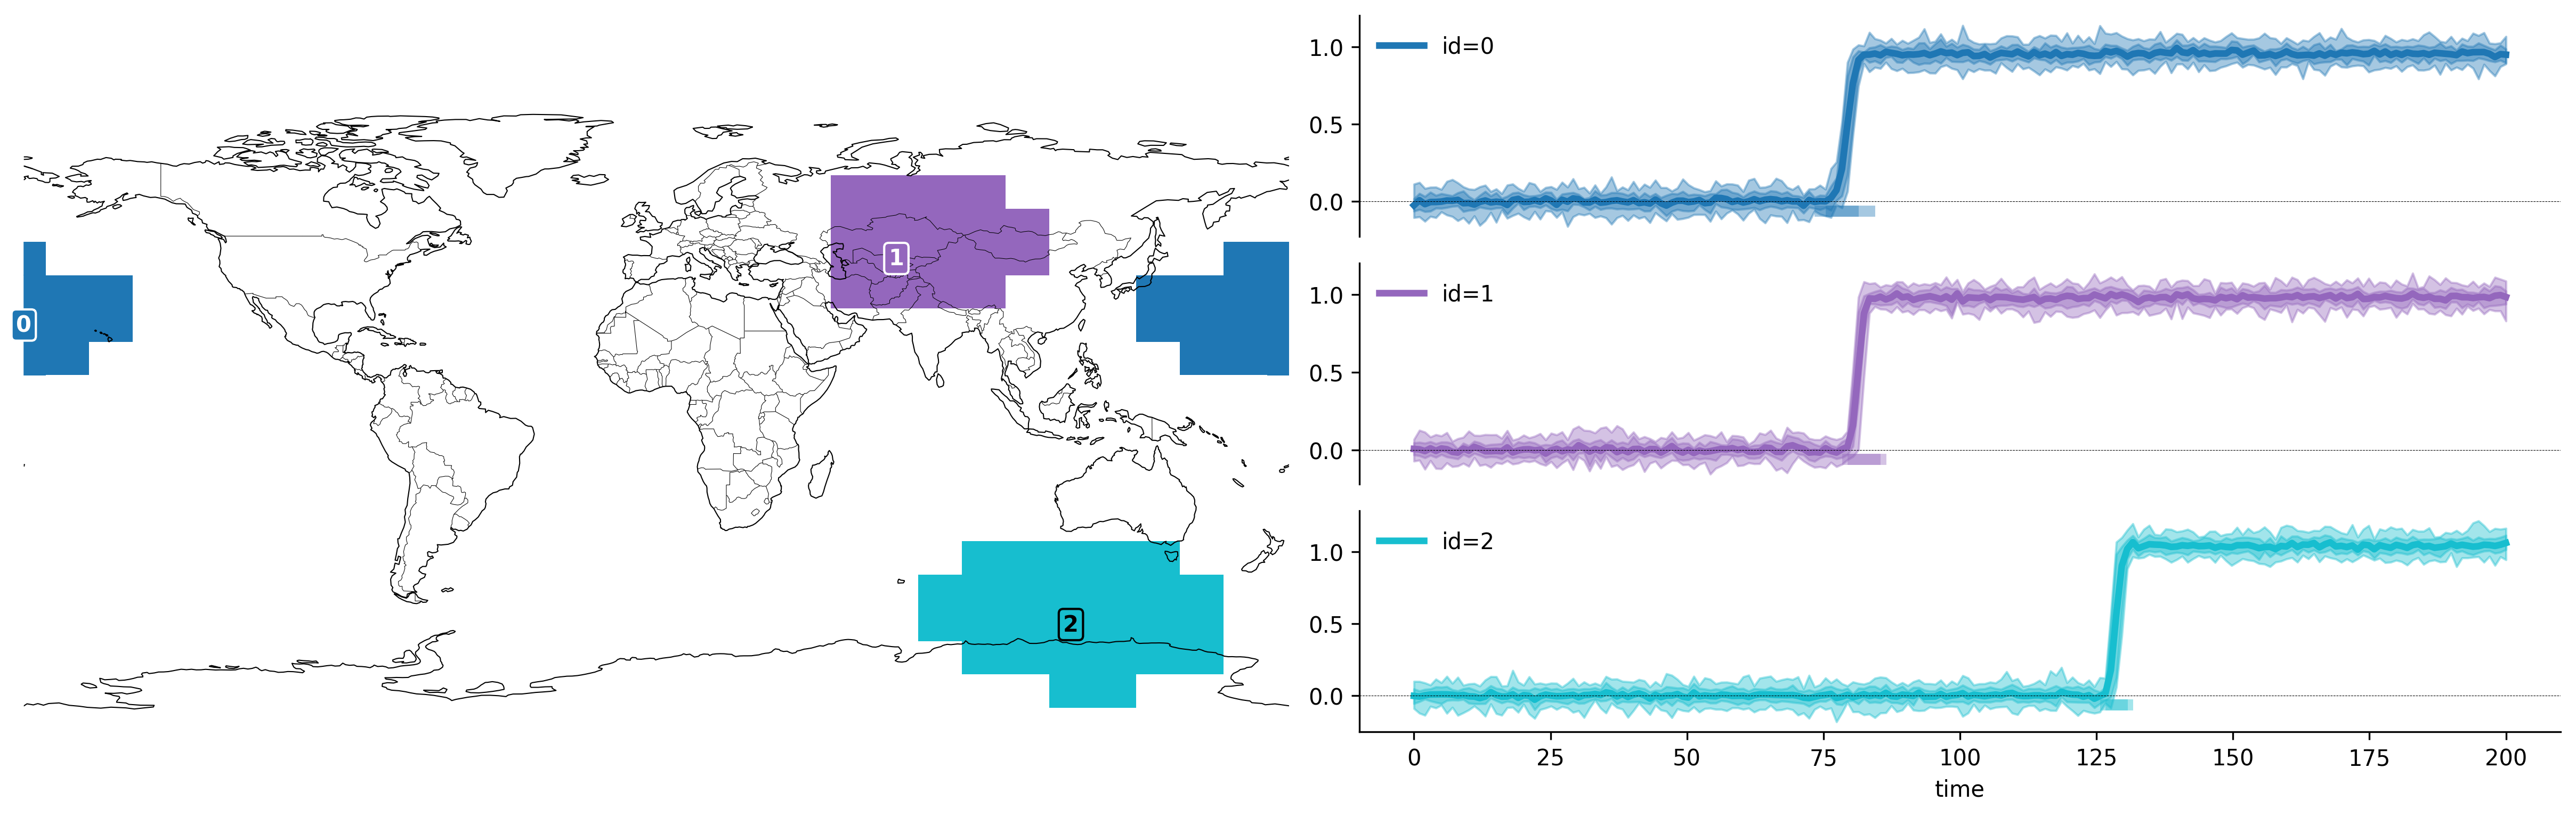

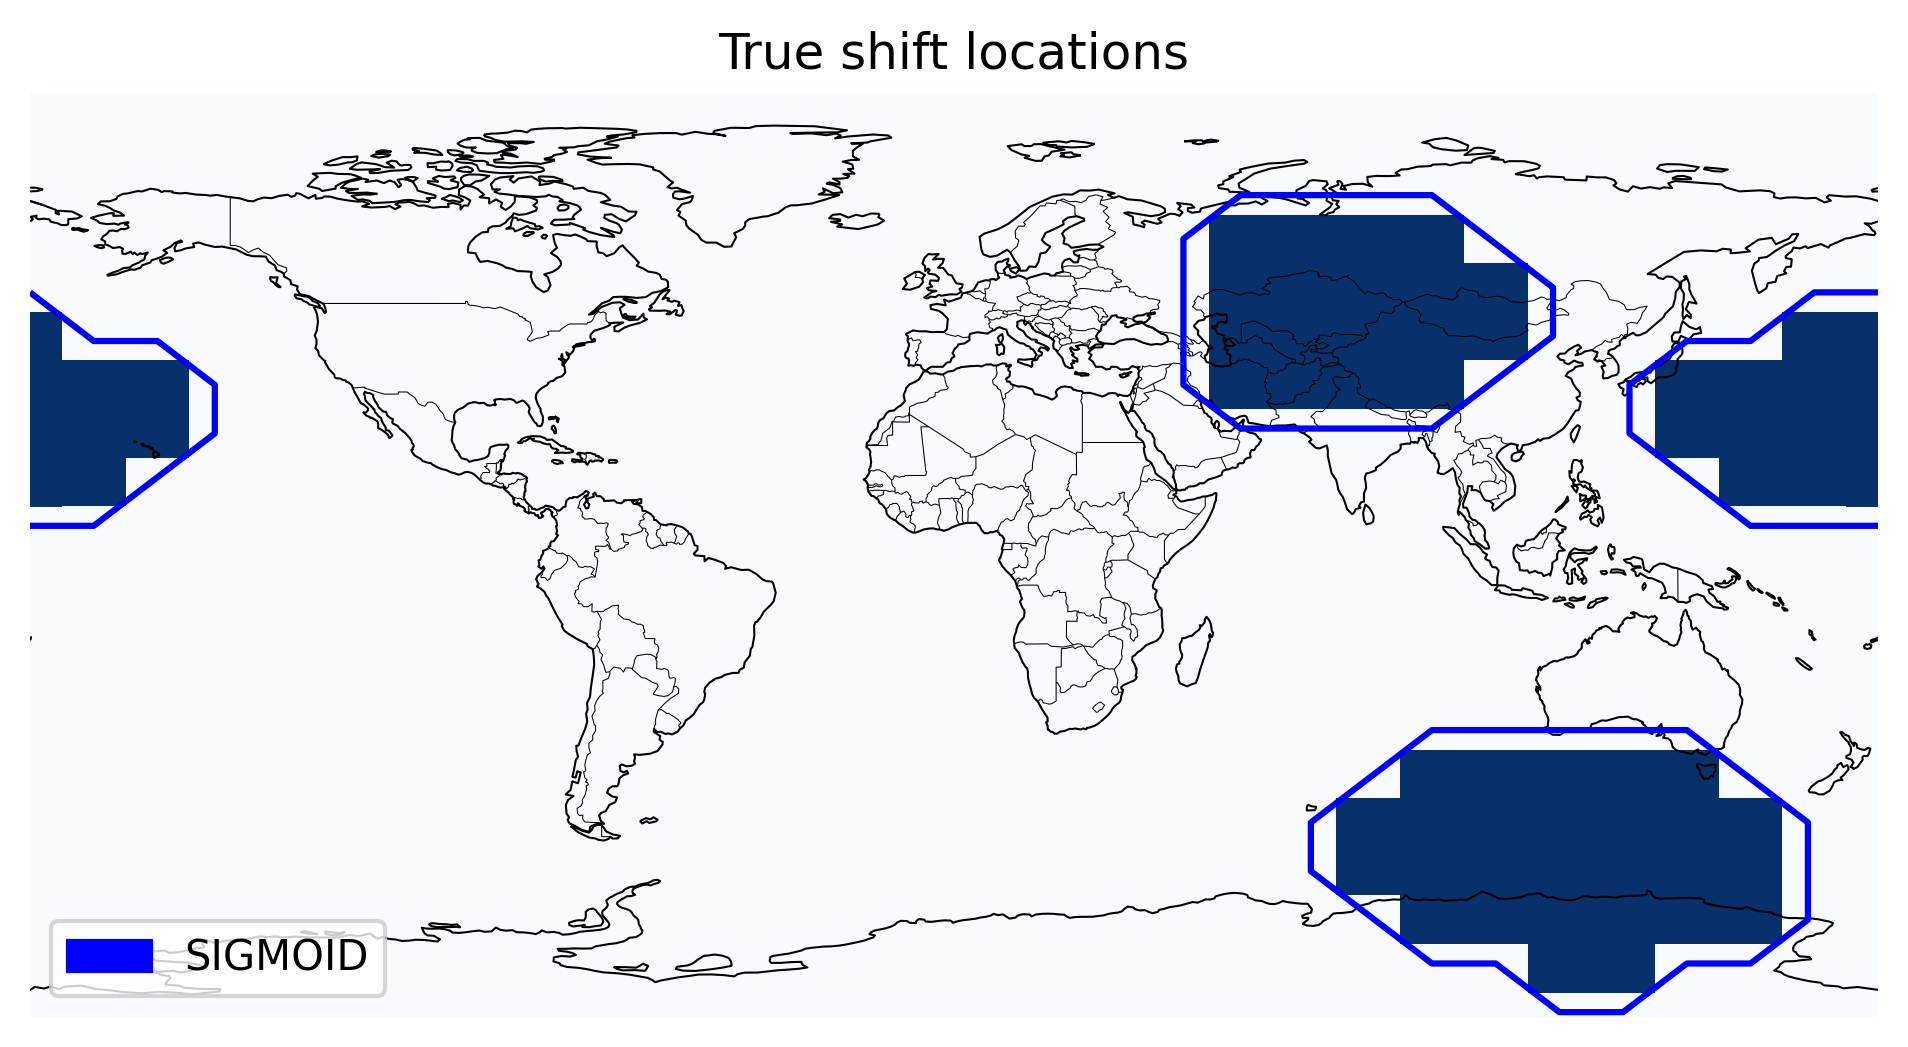

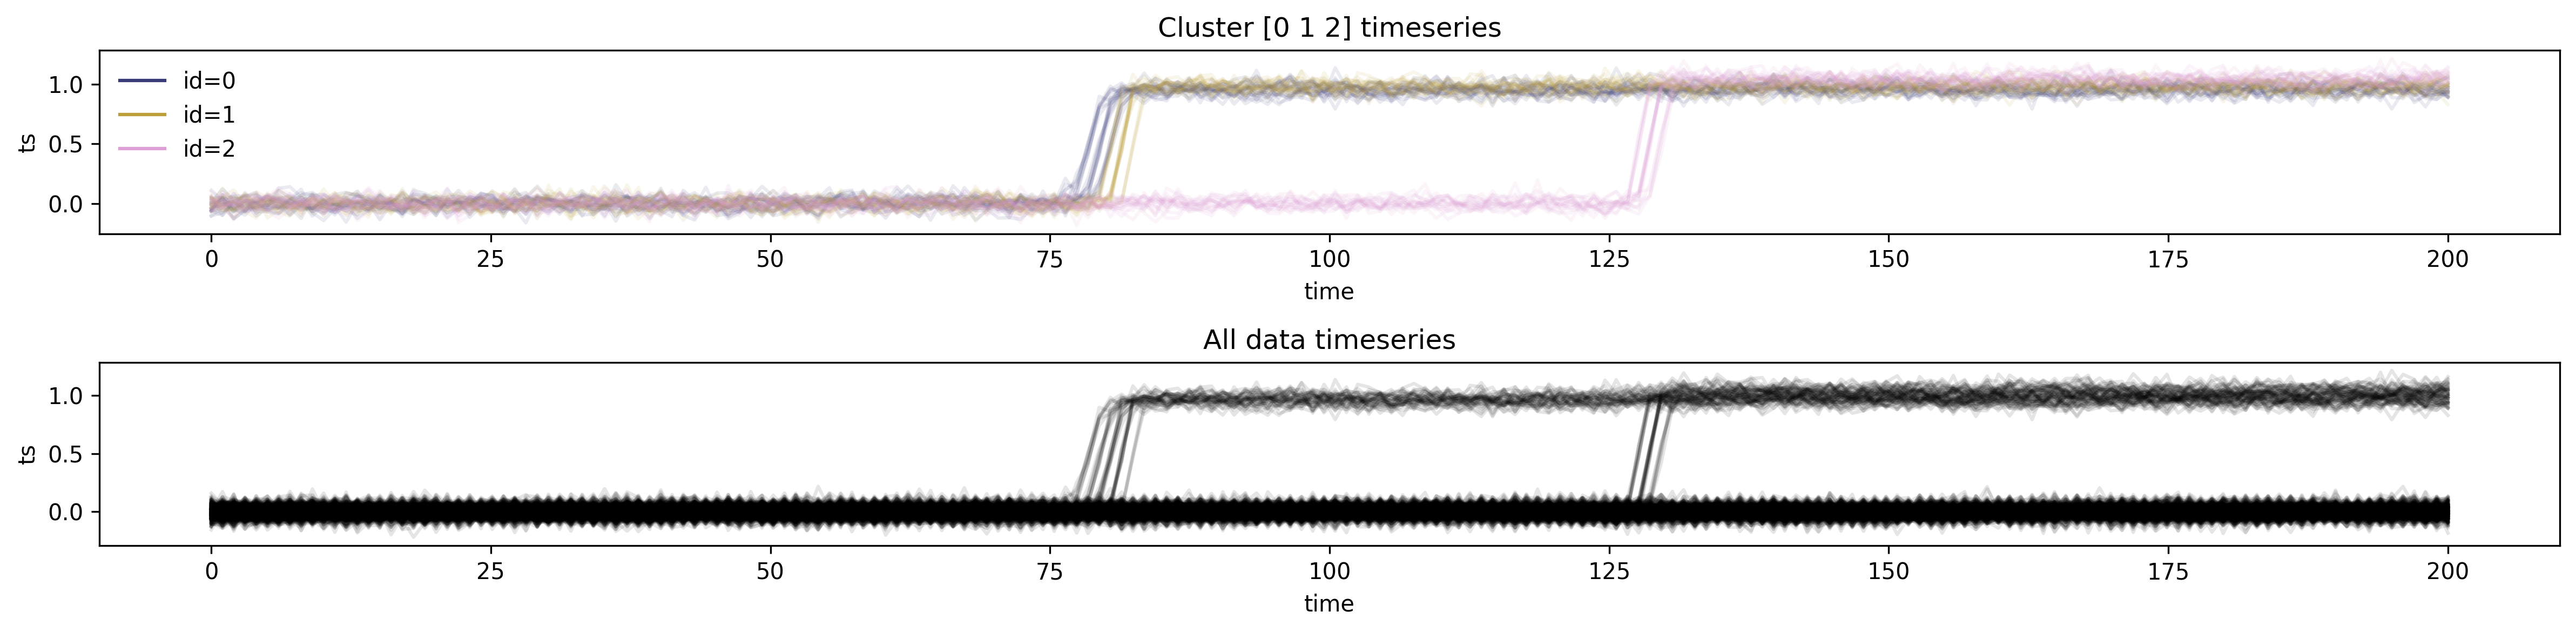

In [8]:
plot(random_seed=2, n_shifts=3)

In the first plot we can see the shift-cluster identified by `TOAD`. The second plot shows the true locations of the shift-cluster created by `PONDS`. The last two plots show the location of the shift events in time, first what `TOAD` found and then what `PONDS` created.